# Thirty days of SIRD filtering with 50 ensemble members

Follow one continuous ensemble from February 28 through March 28, 2020. Day 0 initializes the members from the first observation. On days 1–29 each member advances one day, then receives a correction from the EnKF. The operation log keeps the actual numbers from days 0–9. The final plots show all 50 trajectories across all 30 dates.

In [1]:
from functools import partial
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "Codigos":
    root = root.parent
sys.path.insert(0, str(root / "Codigos"))
from codes import (
    SIRD_OBSERVATION_MATRIX, _balance_compartments, gaussian_rate_walk,
    get_Y_obs, initialize_sird_ensemble, predict_sird_ensemble,
)

START = pd.Timestamp("2020-02-28")
N_DAYS, TRACE_DAYS, ENSEMBLE_SIZE = 30, 10, 50
POPULATION, RECOVERY_DAYS, SEED = 126_014_024, 14, 2026
STATE_SD = np.array([1.0, 0.0, 0.0])  # People, in I, R, D order.
INITIAL_RATES = np.array([0.3508, 0.0714, 0.0015])  # Medians per day.
INITIAL_LOG_SD = np.array([0.35, 0.40, 0.50])
WALK_LOG_SD = np.array([0.12, 0.12, 0.15])  # Per square root of a day.
OBS_COV = np.diag(np.array([10.0, 4.0, 1.5]) ** 2)  # People squared.

dates = pd.date_range(START, periods=N_DAYS, freq="D")
labels = ["S", "I", "R", "D", "beta", "gamma", "delta"]
obs_labels = labels[1:4]
rng = np.random.default_rng(SEED)
rate_step = partial(gaussian_rate_walk, log_step_std=WALK_LOG_SD)

## Build the daily observations

Read admissions in the selected window from the pre-lockdown and first-wave files. Pool the records before counting outcomes so that a death or recovery after the phase boundary is counted on its event date. The active count is $I=C-R-D$, where $C$ is cumulative positive admissions. Recovery is imputed 14 days after admission for cases without a recorded death.

In [2]:
data_dir = root / "Datos"
phases = pd.read_csv(data_dir / "metadata" / "covid_waves_parameters.csv",
                     parse_dates=["Start Date", "End Date"])
used = phases.loc[(phases["Start Date"] <= dates[-1]) & (phases["End Date"] >= dates[0])]
columns = ["FECHA_INGRESO", "FECHA_DEF", "CLASIFICACION_FINAL"]
parts = []
for filename in used["CSV File"]:
    for chunk in pd.read_csv(data_dir / "waves" / filename, usecols=columns, chunksize=100_000):
        admission = pd.to_datetime(chunk["FECHA_INGRESO"], format="%Y-%m-%d")
        parts.append(chunk.loc[admission.between(dates[0], dates[-1])])
records = pd.concat(parts, ignore_index=True)
Y, observed = get_Y_obs(records, dates[0], dates[-1], gamma_time=RECOVERY_DAYS)
assert observed.index.equals(dates)
print(f"{dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d} | {len(used)} phases | {len(Y)} observations")

2020-02-28 to 2020-03-28 | 2 phases | 30 observations


## Initialize the ensemble and the operation log

The first observation centers the draws of $I,R,D$. The filter enforces nonnegative counts, sets $S=N-I-R-D$, and samples positive rates from lognormal distributions. Each numbered member keeps its identity throughout the run. In the log, member 0 denotes a quantity shared by the ensemble. Each numeric column refers to a component of the state. Blank entries mean the operation applies to other components.

In [3]:
rows = []


def record(day, operation, values, components, *, shared=False):
    # One numeric row per member, or one shared row for an ensemble quantity.
    for member, vector in enumerate(np.atleast_2d(values), start=0 if shared else 1):
        rows.append({"day": day, "date": dates[day], "member": member,
                     "operation": operation, **dict(zip(components, vector, strict=True))})


ensemble = initialize_sird_ensemble(Y[0], POPULATION, ENSEMBLE_SIZE, STATE_SD,
                                    INITIAL_RATES, INITIAL_LOG_SD, rng)
history = np.empty((N_DAYS, ENSEMBLE_SIZE, len(labels)))
history[0] = ensemble
record(0, "Read initial observation", Y[0], obs_labels, shared=True)
record(0, "Set initial count SD", STATE_SD, obs_labels, shared=True)
record(0, "Set initial rate medians", INITIAL_RATES, labels[4:], shared=True)
record(0, "Set initial log-rate SD", INITIAL_LOG_SD, labels[4:], shared=True)
record(0, "Initialize balanced counts and positive rates", ensemble, labels)

## Forecast and assimilate one observation per day

1. Draw a Gaussian increment for each log rate. Integrate the SIRD equations over one day using the resulting rates.
2. Form $u^f=(S,I,R,D,\log\beta,\log\gamma,\log\delta)$ and $h=Hu^f=(I,R,D)$. Center the 50 forecasts and divide their anomaly cross-products by 49 to obtain the sample covariances.
3. Compute $K=P_{uh}(P_{hh}+R_{\rm obs})^{-1}$. Draw one observation error $\epsilon_m$ per member and calculate its innovation $v_m=Y+\epsilon_m-h_m$.
4. Apply $u_m^a=u_m^f+Kv_m$, exponentiate the three log rates and balance the compartments. The resulting member starts the following day.

The cells below use the project's initialization and prediction functions. They spell out the analysis so the draws, innovations and corrections written to the log come directly from the update.

In [4]:
def analysis_step(forecast, day):
    u = forecast.copy()
    u[:, 4:] = np.log(forecast[:, 4:])
    h = u @ SIRD_OBSERVATION_MATRIX.T
    centered_u = u - u.mean(axis=0)
    centered_h = h - h.mean(axis=0)
    cross_cov = centered_u.T @ centered_h / (len(u) - 1)
    innovation_cov = centered_h.T @ centered_h / (len(u) - 1) + OBS_COV
    gain = np.linalg.solve(innovation_cov, cross_cov.T).T
    noise = rng.normal(size=h.shape) @ np.linalg.cholesky(OBS_COV).T
    perturbed = Y[day] + noise
    innovation = perturbed - h
    correction = innovation @ gain.T
    updated = u + correction

    if day < TRACE_DAYS:
        record(day, "Select predicted I, R, D", h, obs_labels)
        record(day, "Read observation", Y[day], obs_labels, shared=True)
        for j, channel in enumerate(obs_labels):
            record(day, f"Cross covariance with {channel}", cross_cov[:, j], labels, shared=True)
            record(day, f"Innovation covariance with {channel}", innovation_cov[:, j], obs_labels, shared=True)
            record(day, f"Kalman gain for {channel}", gain[:, j], labels, shared=True)
        record(day, "Draw observation noise", noise, obs_labels)
        record(day, "Add noise to observation", perturbed, obs_labels)
        record(day, "Subtract predicted observation", innovation, obs_labels)
        record(day, "Multiply innovation by Kalman gain", correction, labels)
        record(day, "Update counts and log rates", updated, labels)

    updated[:, 4:] = np.exp(updated[:, 4:])
    _balance_compartments(updated, POPULATION)
    return updated

In [5]:
print("Day  Date        Observed I    Forecast mean I    Analyzed mean I")
print(f"{0:3}  {dates[0]:%Y-%m-%d}  {Y[0, 0]:10.0f}  {'—':>17}  {ensemble[:, 1].mean():17.3f}")
for day in range(1, N_DAYS):
    forecast = predict_sird_ensemble(ensemble, POPULATION, day - 1, day, rate_step, rng)
    if day < TRACE_DAYS:
        record(day, "Start from previous analysis", ensemble, labels)
        log_increment = np.log(forecast[:, 4:] / ensemble[:, 4:])
        record(day, "Advance log rates (realized increment)", log_increment, labels[4:])
        record(day, "Use advanced physical rates", forecast[:, 4:], labels[4:])
        record(day, "Integrate SIRD over one day", forecast[:, :4], labels[:4])
    ensemble = analysis_step(forecast, day)
    history[day] = ensemble
    print(f"{day:3}  {dates[day]:%Y-%m-%d}  {Y[day, 0]:10.0f}  "
          f"{forecast[:, 1].mean():17.3f}  {ensemble[:, 1].mean():17.3f}")
    if day < TRACE_DAYS:
        record(day, "Exponentiate rates and balance counts", ensemble, labels)

operation_log = pd.DataFrame(rows, columns=["day", "date", "member", "operation", *labels])
assert operation_log.day.unique().tolist() == list(range(TRACE_DAYS))
assert operation_log.member.nunique() == ENSEMBLE_SIZE + 1
assert np.isfinite(history).all() and (history[:, :, 4:] > 0).all()
np.testing.assert_allclose(history[:, :, :4].sum(axis=2), POPULATION, rtol=0, atol=1e-6)
print(f"{len(operation_log):,} operation rows for days 0–{TRACE_DAYS - 1}.")

Day  Date        Observed I    Forecast mean I    Analyzed mean I
  0  2020-02-28           2                  —              2.113
  1  2020-02-29           4              2.911              2.923
  2  2020-03-01           6              4.146              4.406
  3  2020-03-02          11              6.382              6.867
  4  2020-03-03          20              9.893             12.555
  5  2020-03-04          30             18.263             23.181
  6  2020-03-05          41             34.011             36.955
  7  2020-03-06          47             54.410             47.373
  8  2020-03-07          54             66.844             58.687
  9  2020-03-08          62             79.918             67.820
 10  2020-03-09          67             87.952             72.577
 11  2020-03-10          84             90.518             85.477
 12  2020-03-11         123            104.925            115.517
 13  2020-03-12         164            146.718            158.058
 14  2020-

## Read the log

Follow active cases for member 1 across the ten logged dates. The innovation equals the observed value plus the sampled error minus the forecast. The correction to $I$ uses all three innovation components and the corresponding row of the gain. Day 0 shows the observation and the initialized count.

In [6]:
def member_trace(member):
    return operation_log.loc[operation_log.member.isin([0, member])]


trace = member_trace(1)
active = trace.pivot(index=["day", "date"], columns="operation", values="I")
daily_example = pd.DataFrame({
    "Observed I": active["Read observation"].combine_first(active["Read initial observation"]),
    "Forecast I": active["Select predicted I, R, D"],
    "Noise in I": active["Draw observation noise"],
    "Innovation in I": active["Subtract predicted observation"],
    "Correction to I": active["Multiply innovation by Kalman gain"],
    "Final I": active["Exponentiate rates and balance counts"].combine_first(
        active["Initialize balanced counts and positive rates"]),
})
print(daily_example.to_string(float_format=lambda x: f"{x:.4f}", na_rep="—"))

                Observed I  Forecast I  Noise in I  Innovation in I  Correction to I  Final I
day date                                                                                     
0   2020-02-28      2.0000           —           —                —                —   1.2069
1   2020-02-29      4.0000      1.4469     -1.8049           0.7482          -0.0123   1.4346
2   2020-03-01      6.0000      1.7699      4.0561           8.2862           0.6668   2.4367
3   2020-03-02     11.0000      3.2429     -2.9288           4.8284           1.3049   4.5478
4   2020-03-03     20.0000      6.9499     -2.9414          10.1087           4.6504  11.6003
5   2020-03-04     30.0000     17.3230      8.8452          21.5222          11.0030  28.3260
6   2020-03-05     41.0000     50.9171    -12.4142         -22.3313         -14.7089  36.2082
7   2020-03-06     47.0000     57.7343      8.9008          -1.8335          -3.3005  54.4339
8   2020-03-07     54.0000     94.4372     -1.9539         -

### Inspect a full update

Change the two selectors below to inspect a different member or date. Columns for beta, gamma and delta use log units for the increment, cross-covariance, gain, correction and log-update rows. The starting and final rows report rates per day. The DataFrame retains full precision for further calculations.

In [7]:
INSPECT_DAY, INSPECT_MEMBER = 1, 1
selected = member_trace(INSPECT_MEMBER)
detail = selected.loc[selected.day.eq(INSPECT_DAY), ["operation", *labels]]
print(detail.to_string(index=False, float_format=lambda x: f"{x:.8g}",
                       formatters={"S": lambda x: f"{x:.6f}"}, na_rep="·"))

                             operation                S            I             R              D           beta          gamma          delta
          Start from previous analysis 126014022.793122    1.2068775             0              0      0.2390442    0.064888627   0.0014233291
Advance log rates (realized increment)                ·            ·             ·              ·   0.0053266274    -0.12469945     0.16263317
           Use advanced physical rates                ·            ·             ·              ·     0.24032089    0.057281225   0.0016746961
           Integrate SIRD over one day 126014022.475118    1.4468683   0.075797253   0.0022160378              ·              ·              ·
              Select predicted I, R, D                ·    1.4468683   0.075797253   0.0022160378              ·              ·              ·
                      Read observation                ·            4             0              0              ·              ·              ·

## Follow all 50 members over 30 dates

Each thin curve follows one analyzed member. The dark curve is the ensemble mean. Dots in the left panels show the reconstructed observations used by the filter.

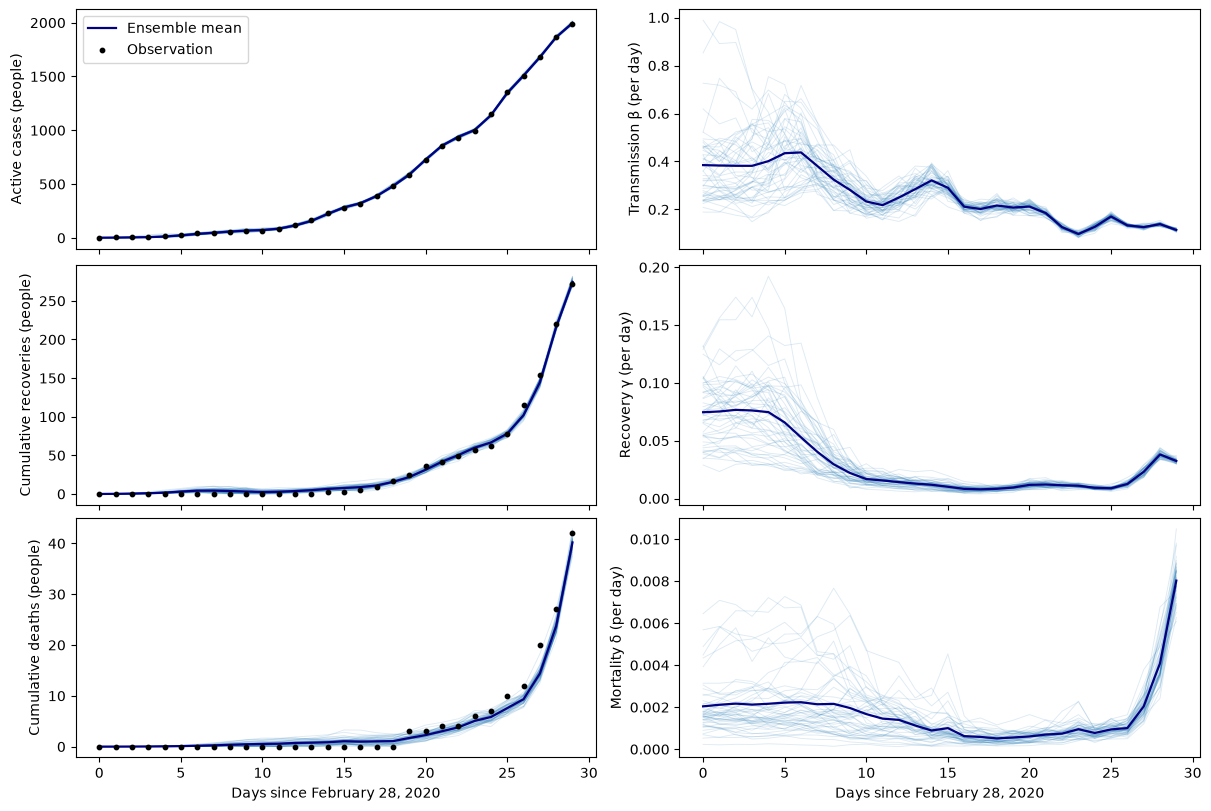

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, constrained_layout=True)
days = np.arange(N_DAYS)
for ax, column, name in zip(axes.flat, [1, 4, 2, 5, 3, 6],
                            ["Active cases (people)", "Transmission β (per day)",
                             "Cumulative recoveries (people)", "Recovery γ (per day)",
                             "Cumulative deaths (people)", "Mortality δ (per day)"]):
    paths = history[:, :, column]
    ax.plot(days, paths, color="tab:blue", alpha=0.15, linewidth=0.65)
    ax.plot(days, paths.mean(axis=1), color="navy", linewidth=1.6, label="Ensemble mean")
    if column in (1, 2, 3):
        ax.scatter(days, Y[:, column - 1], color="black", s=10, label="Observation", zorder=3)
    ax.set_ylabel(name)
axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel("Days since February 28, 2020")
plt.show()